# 32b. Preliminary test results from the notebook 32 checkpoints (no training)

Notebook 32 trained `old_pick`, `near`, `far` and `both` on the tuning seeds 77 and 88 and chose between them on validation. Each run saved its best checkpoint (selected on the validation composite).
This notebook loads those checkpoints and evaluates them on the **test set**, without training anything.

**Status of these numbers.** They are *preliminary*. The decision to prefer `both` was already made on validation (notebook 32), so nothing here feeds back into it. The reported test results will come from the
reporting seeds 42, 123 and 7 (notebook 33); the two sets are not averaged together. Nothing is retrained or selected in this notebook.

**Safety check.** For every run the validation accuracy is recomputed from the checkpoint and must match the value saved by notebook 32, so a wrong or stale checkpoint stops the notebook instead of producing a table.

In [1]:
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

REPO = os.environ.get("BADMINTON_REPO", "/workspace/badminton-honours-project")
DATA = os.environ.get("BADMINTON_DATA", "/workspace/data")
OUTPUTS = os.environ.get("BADMINTON_OUTPUTS", "/workspace/outputs")
for p in (REPO, f"{REPO}/two_player"):
    sys.path.insert(0, p)
import dataset as ds
import training as tr
import two_person as tp

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(torch.__version__, device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

2.1.0+cu118 cuda NVIDIA GeForce RTX 4090


In [2]:
OLD_KP = f"{DATA}/keypoints_interp"
SEL_INTERP = f"{DATA}/keypoints_sel_interp"
OUT = f"{OUTPUTS}/experiments/two_player"
SEEDS = [77, 88]
USE_COURT = True
FAR_COVERAGE_MIN = 0.5
DRILL_PATTERN = r"2023"
RARE_THRESHOLD = 150
N_BOOT = 2000
ARMS = {"old_pick": dict(root=OLD_KP, persons=(0,)), "near": dict(root=SEL_INTERP, persons=(0,)),
        "far": dict(root=SEL_INTERP, persons=(1,)), "both": dict(root=SEL_INTERP, persons=(0, 1))}

with open(f"{REPO}/configs/stgcn_recipe.json") as f:
    RECIPE = json.load(f)

clean_log = pd.read_csv(f"{DATA}/keypoints_sel_interp_log.csv").set_index("filepath")
manifest = ds.load_filtered_manifest(f"{DATA}/split_manifest.csv", f"{DATA}/extraction_log.csv",
                                     f"{DATA}/keypoints_interp_log.csv", RECIPE["min_native_frames"])
manifest = manifest[manifest["filepath"].isin(clean_log.index)].reset_index(drop=True)
manifest = manifest[clean_log.loc[manifest["filepath"], "near_cov"].to_numpy() > 0].reset_index(drop=True)
manifest["far_found"] = clean_log.loc[manifest["filepath"], "far_cov"].to_numpy() >= FAR_COVERAGE_MIN
manifest["drill"] = manifest["filepath"].str.contains(DRILL_PATTERN)
class_names = sorted(manifest["class_name"].unique())
class_to_id = {c: i for i, c in enumerate(class_names)}
K = len(class_names)
IN_CH = tp.n_channels(USE_COURT)
train_counts = manifest[manifest["split"] == "train"]["class_name"].value_counts().reindex(class_names)
rare_idx = [i for i, c in enumerate(class_names) if train_counts[c] < RARE_THRESHOLD]
res32 = pd.read_csv(f"{OUT}/results.csv")
print(manifest["split"].value_counts().to_dict(), f"| {K} classes")

manual review: dropped 4 clips
short clip rule: dropped 4 train clips with fewer than 5 real frames
7810 clips remain (train 6247, test 782, val 781)
{'train': 6247, 'test': 782, 'val': 781} | 18 classes


## Evaluate the saved checkpoints

In [3]:
rows, preds = [], {}
forward = tp.make_forward(USE_COURT)
for arm, cfg in ARMS.items():
    for seed in SEEDS:
        run = f"two_{arm}_s{seed}"
        loaders = tp.build_loaders(manifest, cfg["root"], class_to_id, cfg["persons"], "none", seed=seed, batch_size=RECIPE["batch_size"],
                                   num_workers=0, eval_workers=4, splits=("train", "val", "test"))
        model = tp.PersonsSTGCN(IN_CH, K, len(cfg["persons"])).to(device)
        model.load_state_dict(torch.load(f"{OUT}/{run}/{run}.pt", map_location=device))
        val = tr.evaluate(model, loaders["val"], forward, device)
        test = tr.evaluate(model, loaders["test"], forward, device)
        saved = res32.loc[(res32["arm"] == arm) & (res32["seed"] == seed)].iloc[0]
        assert abs(val["top1"] - saved["val_top1"]) < 1e-3 and abs(val["mca"] - saved["val_mca"]) < 1e-3, \
            f"{run}: validation from the checkpoint ({val['top1']:.4f}) does not match the saved run ({saved['val_top1']:.4f})"
        order = np.argsort(test["filepaths"])
        preds[(arm, seed)] = (np.array(test["filepaths"])[order], test["labels"][order], test["preds"][order])
        rows.append({"arm": arm, "seed": seed, "test_top1": test["top1"], "test_top5": test["top5"], "test_mca": test["mca"],
                     "test_macro_f1": test["macro_f1"], "val_top1": val["top1"], "val_mca": val["mca"]})
        print(f"{run}: val {val['top1']:.4f} (saved {saved['val_top1']:.4f})  test top1 {test['top1']:.4f}  mca {test['mca']:.4f}")
        del model, loaders
        torch.cuda.empty_cache()
prelim = pd.DataFrame(rows)
prelim.to_csv(f"{OUT}/test_prelim_tuning_seeds.csv", index=False)

two_old_pick_s77: val 0.7490 (saved 0.7490)  test top1 0.7289  mca 0.5600
two_old_pick_s88: val 0.7414 (saved 0.7414)  test top1 0.7251  mca 0.5419
two_near_s77: val 0.7567 (saved 0.7567)  test top1 0.7084  mca 0.5523
two_near_s88: val 0.7503 (saved 0.7503)  test top1 0.7161  mca 0.5576
two_far_s77: val 0.7029 (saved 0.7029)  test top1 0.7340  mca 0.5580
two_far_s88: val 0.7055 (saved 0.7055)  test top1 0.7123  mca 0.5369
two_both_s77: val 0.7964 (saved 0.7964)  test top1 0.7788  mca 0.6424
two_both_s88: val 0.7939 (saved 0.7939)  test top1 0.7775  mca 0.6418


In [4]:
cols = ["test_top1", "test_top5", "test_mca", "test_macro_f1", "val_top1", "val_mca"]
m, s = prelim.groupby("arm")[cols].mean().reindex(list(ARMS)), prelim.groupby("arm")[cols].std().reindex(list(ARMS))
show = (100 * m).round(2).astype(str) + " +/- " + (100 * s).round(2).astype(str)
print("PRELIMINARY test results, tuning seeds", SEEDS, "(points). Li et al. ST-GCN: top1 74.41, top5 93.76, MCA 61.44")
show

PRELIMINARY test results, tuning seeds [77, 88] (points). Li et al. ST-GCN: top1 74.41, top5 93.76, MCA 61.44


,test_top1,test_top5,test_mca,test_macro_f1,val_top1,val_mca
arm,,,,,,
old_pick,72.7 +/- 0.27,94.37 +/- 0.72,55.1 +/- 1.28,56.31 +/- 1.86,74.52 +/- 0.54,62.55 +/- 1.68
near,71.23 +/- 0.54,94.76 +/- 0.72,55.49 +/- 0.38,57.13 +/- 1.07,75.35 +/- 0.45,62.74 +/- 1.34
far,72.31 +/- 1.54,93.48 +/- 0.0,54.74 +/- 1.49,56.52 +/- 2.14,70.42 +/- 0.18,54.92 +/- 0.67
both,77.81 +/- 0.09,96.29 +/- 0.0,64.21 +/- 0.05,66.81 +/- 0.14,79.51 +/- 0.18,67.61 +/- 0.21


In [5]:
prelim.sort_values(["arm", "seed"]).assign(**{c: lambda d, c=c: (100 * d[c]).round(2) for c in cols})

,arm,seed,test_top1,test_top5,test_mca,test_macro_f1,val_top1,val_mca
6,both,77,77.88,96.29,64.24,66.91,79.64,67.46
7,both,88,77.75,96.29,64.18,66.71,79.39,67.76
4,far,77,73.40,93.48,55.80,58.03,70.29,55.39
5,far,88,71.23,93.48,53.69,55.00,70.55,54.44
2,near,77,70.84,95.27,55.23,56.37,75.67,63.69
3,near,88,71.61,94.25,55.76,57.89,75.03,61.79
0,old_pick,77,72.89,94.88,56.00,57.63,74.90,63.73
1,old_pick,88,72.51,93.86,54.19,55.00,74.14,61.36


## Differences with intervals

Paired bootstrap over test clips (the same resampled clips scored for both arms and averaged over the two seeds). The intervals reflect which test clips were drawn; with only two seeds they do not include seed to seed variation.

In [6]:
files = preds[("near", SEEDS[0])][0]
y = preds[("near", SEEDS[0])][1]
for key, (f, lab, _) in preds.items():
    assert (f == files).all() and (lab == y).all()
Y = {arm: {s: preds[(arm, s)][2] for s in SEEDS} for arm in ARMS}


def top1(yt, yp):
    return float((yt == yp).mean())


def mca(yt, yp):
    tot = np.bincount(yt, minlength=K)
    hit = np.bincount(yt[yt == yp], minlength=K)
    return float((hit[tot > 0] / tot[tot > 0]).mean())


def seed_mean(arm, idx, fn):
    return float(np.mean([fn(y[idx], Y[arm][s][idx]) for s in SEEDS]))


def boot_diff(a, b, fn, n_boot=N_BOOT, seed=0):
    rng = np.random.RandomState(seed)
    full = np.arange(len(y))
    point = seed_mean(a, full, fn) - seed_mean(b, full, fn)
    d = np.empty(n_boot)
    for i in range(n_boot):
        idx = rng.randint(0, len(y), len(y))
        d[i] = seed_mean(a, idx, fn) - seed_mean(b, idx, fn)
    lo, hi = np.percentile(d, [2.5, 97.5])
    return point, lo, hi


rows = []
for a, b in (("both", "near"), ("both", "old_pick"), ("near", "old_pick"), ("far", "near")):
    row = {"comparison": f"{a} - {b}"}
    for fn, label in ((top1, "top1"), (mca, "mca")):
        pt, lo, hi = boot_diff(a, b, fn)
        row[f"{label} (pts)"] = round(100 * pt, 2)
        row[f"{label} 95% CI"] = f"[{100 * lo:+.2f}, {100 * hi:+.2f}]"
    rows.append(row)
pd.DataFrame(rows)

,comparison,top1 (pts),top1 95% CI,mca (pts),mca 95% CI
0,both - near,6.59,"[+4.48, +8.82]",8.72,"[+5.65, +12.09]"
1,both - old_pick,5.12,"[+3.01, +7.29]",9.11,"[+5.57, +12.79]"
2,near - old_pick,-1.47,"[-3.07, +0.19]",0.40,"[-2.13, +3.15]"
3,far - near,1.09,"[-1.47, +3.84]",-0.75,"[-4.41, +2.77]"


## Where the gain lands

In [7]:
test_part = manifest[manifest["split"] == "test"].set_index("filepath").loc[files]
subs = {"all": np.ones(len(files), bool), "far found": test_part["far_found"].to_numpy(), "far not found": ~test_part["far_found"].to_numpy(),
        "match clips": ~test_part["drill"].to_numpy(), "drill clips": test_part["drill"].to_numpy()}
rows = []
for arm in ARMS:
    row = {"arm": arm}
    for name, mk in subs.items():
        row[name] = round(100 * float(np.mean([top1(y[mk], Y[arm][s][mk]) for s in SEEDS])), 2)
    rows.append(row)
rows.append({"arm": "n clips", **{k: int(v.sum()) for k, v in subs.items()}})
pd.DataFrame(rows)

,arm,all,far found,far not found,match clips,drill clips
0,old_pick,72.70,72.82,66.67,72.75,71.79
1,near,71.23,71.32,66.67,70.46,85.90
2,far,72.31,72.95,40.00,72.07,76.92
3,both,77.81,77.97,70.00,76.78,97.44
4,n clips,782.00,767.00,15.00,743.00,39.00


In [8]:
def recall_by_class(arm):
    r = np.zeros((len(SEEDS), K))
    for i, s in enumerate(SEEDS):
        for k in range(K):
            mk = y == k
            r[i, k] = (Y[arm][s][mk] == k).mean() if mk.any() else np.nan
    return r.mean(axis=0)


rec = pd.DataFrame({arm: recall_by_class(arm) for arm in ARMS}, index=[c.split("_", 1)[-1] for c in class_names])
common_idx = [k for k in range(K) if k not in rare_idx]
group = pd.DataFrame({arm: {"limited sample recall": rec[arm].iloc[rare_idx].mean(), "common recall": rec[arm].iloc[common_idx].mean()} for arm in ARMS}).T
print("limited sample classes:", [class_names[i].split("_", 1)[-1] for i in rare_idx])
(100 * group).round(2)

limited sample classes: ['Cross Court Flight', 'Tap Smash', 'Transitional Slice', 'Rush Shot', 'Defensive Clear', 'Defensive Drive', 'Rear Court Flat Drive', 'Short Flat Shot']


,limited sample recall,common recall
old_pick,34.58,71.50
near,38.67,68.95
far,34.90,70.61
both,52.75,73.38


In [9]:
per_class = (100 * rec).round(1)
per_class["support"] = np.bincount(y, minlength=K)
per_class["both - near"] = (per_class["both"] - per_class["near"]).round(1)
per_class.sort_values("both - near", ascending=False)

,old_pick,near,far,both,support,both - near
Defensive Clear,27.3,18.2,27.3,63.6,11,45.4
Cross Court Flight,6.2,3.1,12.5,37.5,16,34.4
Cut,70.3,66.1,81.4,82.2,59,16.1
Transitional Slice,15.4,15.4,0.0,30.8,13,15.4
Clear,79.5,74.7,78.4,87.9,95,13.2
Lift,69.1,67.1,71.1,76.3,76,9.2
Tap Smash,18.2,18.2,18.2,27.3,11,9.1
Smash,89.0,87.2,89.0,93.3,82,6.1
Drop Shot,82.1,82.1,77.8,87.7,81,5.6
Rear Court Flat Drive,29.2,45.8,50.0,50.0,12,4.2


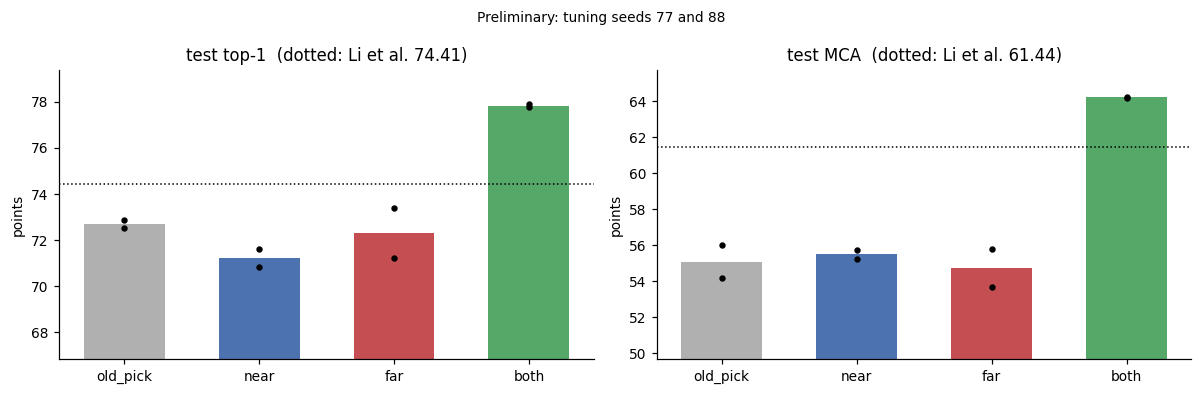

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
arm_colors = {"old_pick": "#b0b0b0", "near": "#4c72b0", "far": "#c44e52", "both": "#55a868"}
for ax, col, title, ref in zip(axes, ("test_top1", "test_mca"), ("test top-1", "test MCA"), (74.41, 61.44)):
    for j, arm in enumerate(ARMS):
        v = 100 * prelim[prelim["arm"] == arm][col].to_numpy()
        ax.bar(j, v.mean(), color=arm_colors[arm], width=0.6)
        ax.scatter([j] * len(v), v, color="k", s=10, zorder=3)
    ax.axhline(ref, color="k", ls=":", lw=1)
    ax.set_xticks(range(len(ARMS)), list(ARMS))
    ax.set_ylim(100 * prelim[col].min() - 4, max(100 * prelim[col].max(), ref) + 1.5)
    ax.set_title(title + f"  (dotted: Li et al. {ref})"); ax.set_ylabel("points")
fig.suptitle("Preliminary: tuning seeds 77 and 88", fontsize=9)
fig.tight_layout()
plt.show()

## How to read this

- These are **preliminary** numbers on the tuning seeds. The reported results are those of notebook 33 (reporting seeds 42, 123, 7).
- `near` against `old_pick` is what fixing the pick is worth on its own; `both` against `near` is the value of the second player.
- With two seeds and 782 test clips, differences under about 1 point are within noise. The seed to seed spread is shown in the table (the +/- values).
- The validation numbers of notebook 32 remain the basis for the choice of `both`; the test set was not used for any choice.